# UNIVERSIDAD TÉCNICA PARTICULAR DE LOJA (UTPL)
## Carrera de Ciencias de la Computación
### Asignatura: Interoperabilidad y Explotación de Datos en Ecosistemas Heterogéneos
**Docente:** Dra. Janneth Alexandra Chicaiza Espinosa  
**Integrantes:** Alex Gutiérrez, David Emanuel Manotoa Tandazo  
**Fecha:** 13 de noviembre de 2026  

---
# Entregable 2: Extracción, Limpieza, Integración y Modelo Tentativo del Grafo de Conocimiento
**Dominio:** Smart Cities — Movilidad Urbana Sostenible (CityBikes Bicing) y Calidad del Aire (Open-Meteo CAMS) en Barcelona, España.

## 1. Introducción y Objetivos del Entregable
El presente entregable implementa la fase técnica de adquisición, perfilado, depuración y enlace de datos procedentes de dos fuentes abiertas heterogéneas para la ciudad de Barcelona:
1. **Fuente 1 (Movilidad Activa):** API REST de CityBikes (Red metropolitana Bicing de Barcelona).
2. **Fuente 2 (Medio Ambiente):** API REST de Open-Meteo Air Quality (Modelos de dispersión regional europea Copernicus CAMS).

### Objetivos Específicos:
- Implementar funciones reproducibles de extracción con captura de procedencia (URL, timestamp UTC, HTTP status).
- Resolver anomalías detectadas en la auditoría técnica (timestamps con `+00:00Z`, normalización de nombres con dobles espacios y delimitadores, desanidación de series temporales vectoriales).
- Enlazar geoespacialmente las estaciones de bicicletas con las celdas del modelo CAMS (~11 km de resolución) y temporalmente mediante ventanas horarias en UTC.
- Diseñar el modelo de datos tentativo en RDF/OWL/SOSA reutilizando vocabularios estándar de la W3C (`schema:`, `sosa:`, `geo:`, `dcterms:`).
- Producir tablas resumen y visualizaciones estadísticas y geoespaciales de los datos consolidados.

In [ ]:
# Configuración de entorno y carga de módulos del proyecto
import sys
from pathlib import Path

# Asegurar acceso al paquete src/bcn_kg
DIR_BASE = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(DIR_BASE / 'src') not in sys.path:
    sys.path.insert(0, str(DIR_BASE / 'src'))

import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import rdflib

from bcn_kg.extraccion import extraer_citybikes, extraer_openmeteo_celdas, registrar_procedencia
from bcn_kg.limpieza import procesar_raw_citybikes, validar_calidad_citybikes, desanidar_hourly_openmeteo
from bcn_kg.enlace import enlazar_estaciones_con_celdas, enlazar_estado_con_observaciones, haversine_km

print('Módulos de bcn_kg cargados exitosamente.')

## 2. Extracción de Datos desde Fuentes Abiertas (APIs REST)
A continuación se describe y ejecuta la extracción sobre los endpoints oficiales. Cada respuesta se empaqueta en un **sobre de procedencia** que preserva el JSON crudo inalterado, su URL exacta, fecha/hora UTC de consulta y código de estado HTTP.

In [ ]:
# Verificación de los archivos crudos almacenados en el pipeline
dir_raw = DIR_BASE / 'data' / 'raw'
archivos_cb = sorted(list((dir_raw / 'citybikes').glob('citybikes_bicing_*.json')))
archivos_om = sorted(list((dir_raw / 'openmeteo').glob('openmeteo_cams_*.json')))

print(f'Total capturas CityBikes disponibles: {len(archivos_cb)}')
print(f'Total capturas Open-Meteo disponibles: {len(archivos_om)}')

# Cargar la captura más reciente para demostración
with open(archivos_cb[-1], 'r', encoding='utf-8') as f:
    raw_cb = json.load(f)

with open(archivos_om[-1], 'r', encoding='utf-8') as f:
    raw_om = json.load(f)

print(f"CityBikes URL: {raw_cb['url']} | HTTP Status: {raw_cb['http_status']} | Extraído UTC: {raw_cb['extraido_utc']}")
print(f"Open-Meteo URL: {raw_om['url'][:80]}... | HTTP Status: {raw_om['http_status']}")

## 3. Perfilado de Calidad y Limpieza de Heterogeneidades
Durante la auditoría técnica adversarial se identificaron particularidades críticas en los datos originales:
1. **Dispersión de marcas temporales en CityBikes (Hallazgo H2):** Se comprobó empíricamente que las estaciones reportan marcas dentro del mismo segundo; por tanto, el campo `timestamp` representa la ingesta del feed y no telemetría de sensor individual.
2. **Formato inválido de marca temporal (Hallazgo H3):** Presencia de la cadena `+00:00Z` corregida mediante la función `parsear_ts_citybikes`.
3. **Normalización de cadenas:** Espacios superfluos y caracteres especiales limpiados con `normalizar_texto`.
4. **Desanidación columnar:** Conversión de las matrices vectoriales paralelas de Open-Meteo en tuplas atómicas homogéneas.

In [ ]:
# Procesar catálogo de estaciones, estado dinámico y operadores
df_estaciones, df_estado, df_operadores = procesar_raw_citybikes(raw_cb['payload'])
df_celdas, df_observaciones = desanidar_hourly_openmeteo(raw_om['payload'])

# Auditoría de calidad física y aritmética
df_incidencias = validar_calidad_citybikes(df_estaciones, df_estado)

print('=== ESTADÍSTICAS DEL PROCESAMIENTO ===')
print(f'Estaciones físicas identificadas: {len(df_estaciones)}')
print(f'Observaciones de disponibilidad:    {len(df_estado)}')
print(f'Operadores de la red identificados: {len(df_operadores)}')
print(f'Celdas atmosféricas detectadas:     {len(df_celdas)}')
print(f'Observaciones horarias ambientales: {len(df_observaciones)}')
print(f'Incidencias de calidad detectadas:  {len(df_incidencias)}')

display(df_estaciones[['id_estacion', 'nombre_original', 'nombre_limpio', 'latitud', 'longitud']].head(5))

## 4. Estrategia de Enlace Semántico (Espacial y Temporal)
- **Enlace Espacial (Nodo Puente - Celda CAMS):** Dado que la resolución de CAMS es de 0.1° (~11 km), las estaciones se asocian a su celda contenedora mediante la relación `vocab:contenidaEnCelda`. Se calcula la distancia geodésica mediante la fórmula de Haversine (`vocab:distanciaACentroideKm`).
- **Enlace Temporal:** Sincronización en UTC uniendo cada estado con el registro ambiental más cercano dentro de una tolerancia de 30 minutos.

In [ ]:
# Ejecutar enlace espacial
df_enlace_esp = enlazar_estaciones_con_celdas(df_estaciones, df_celdas)

# Ejecutar enlace temporal
df_integrado, metricas_temp = enlazar_estado_con_observaciones(
    df_estado=df_estado,
    df_enlace_espacial=df_enlace_esp,
    df_observaciones=df_observaciones,
    tolerancia_minutos=30
)

print('=== MÉTRICAS DE ENLACE TEMPORAL ===')
for k, v in metricas_temp.items():
    print(f'  {k}: {v}')

display(df_integrado[['id_estacion', 'captura_utc', 'id_celda', 'hora_utc', 'delta_minutos', 'free_bikes', 'no2', 'pm10', 'pm2_5']].head(5))

## 5. Modelo de Datos Tentativo para el Grafo de Conocimiento
El modelo tentativo formaliza la integración reutilizando vocabularios estándar de la W3C (`schema:`, `sosa:`, `geo:`, `dcterms:`) y definiendo términos propios bajo el prefijo `vocab:`. A continuación se valida sintácticamente el archivo ontológico `vocab.ttl` con la librería `rdflib`.

In [ ]:
# Carga y validación sintáctica del vocabulario RDF en Turtle
ruta_vocab = DIR_BASE / 'modelo' / 'vocab.ttl'
g = rdflib.Graph()
g.parse(ruta_vocab, format='turtle')

print(f'Vocabulario cargado exitosamente. Total de tripletas axiomáticas: {len(g)}')

# Listar clases y propiedades modeladas
clases = sorted([str(s).split('#')[-1] for s in g.subjects(rdflib.RDF.type, rdflib.RDFS.Class)])
props = sorted([str(s).split('#')[-1] for s in g.subjects(rdflib.RDF.type, rdflib.RDF.Property)])

print(f'Clases ontológicas ({len(clases)}): {clases}')
print(f'Propiedades definidas ({len(props)}): {props}')

### Diagrama Conceptual del Modelo de Datos Tentativo
A continuación se genera y visualiza el esquema arquitectónico completo del Grafo de Conocimiento, diferenciando por color el vocabulario de cada clase (`sosa:`, `schema:`, `geo:`, `dcterms:`), señalando con `◆` los términos propios (`vocab:`) y con líneas punteadas las relaciones obtenidas por consulta y enlace espacio-temporal.

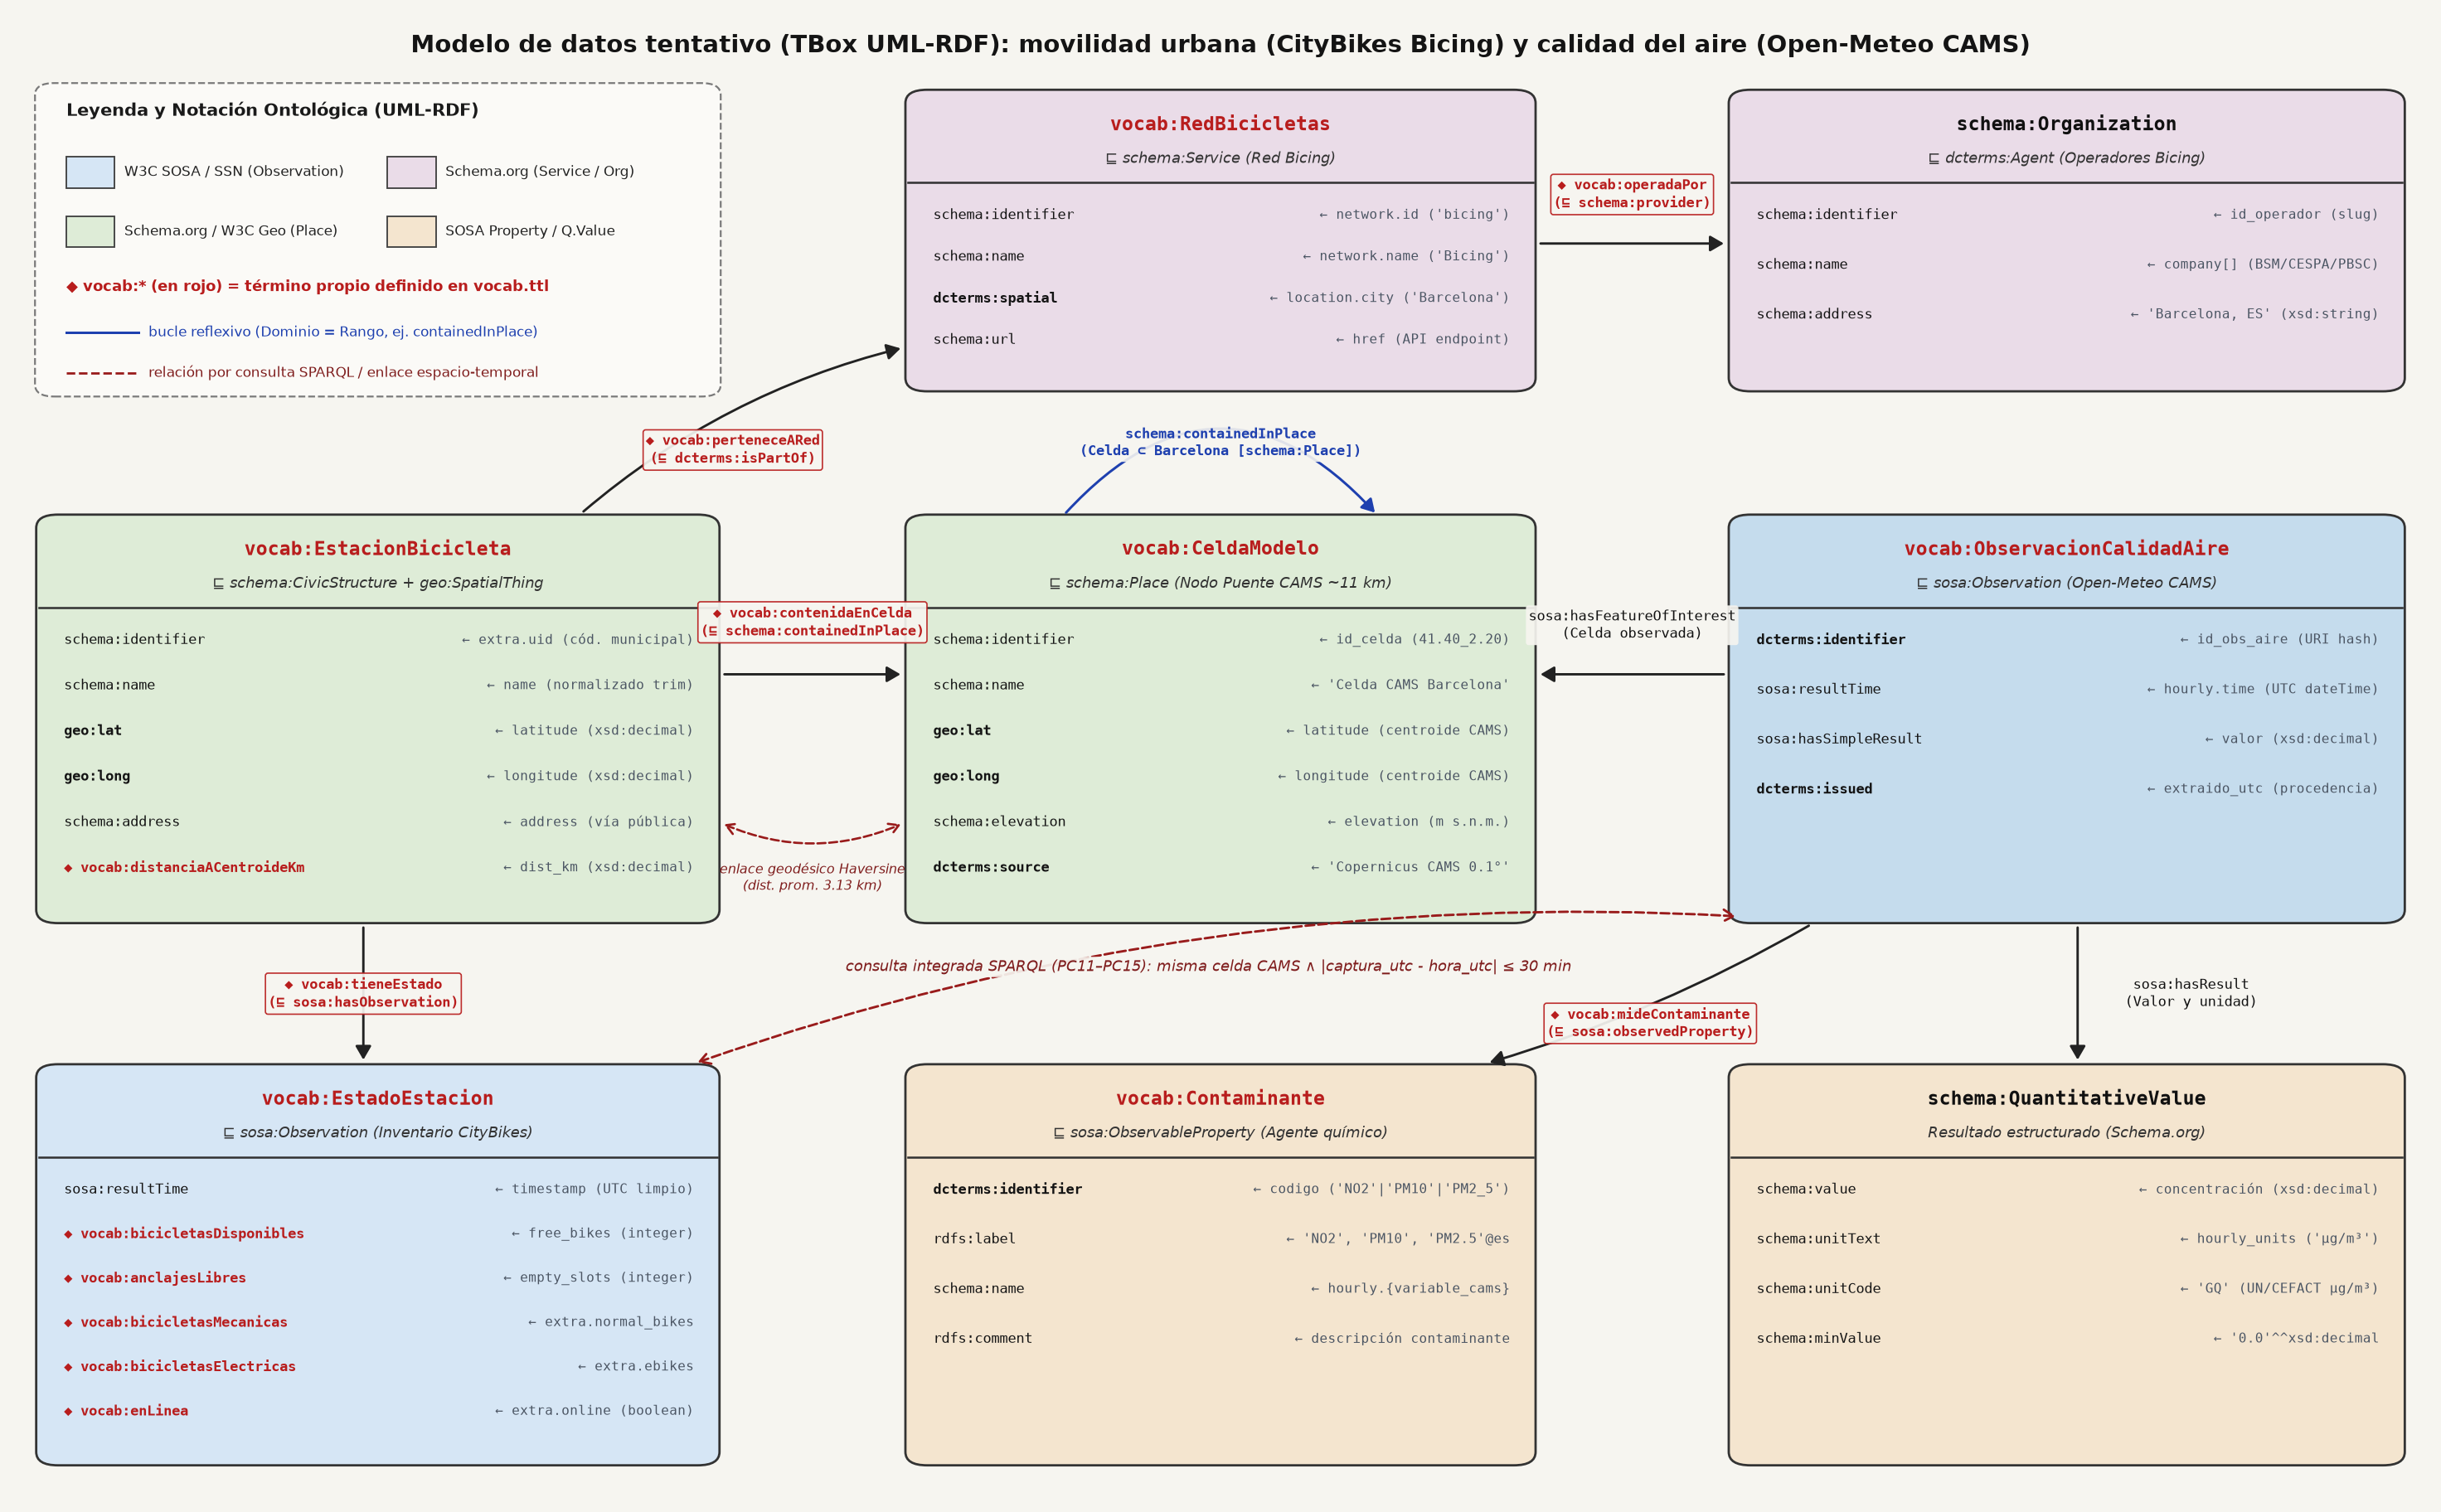

In [6]:
# Representación gráfica del Modelo de Datos Tentativo (RDF / OWL / SOSA)
from bcn_kg.diagrama import dibujar_modelo

dibujar_modelo(DIR_BASE / 'modelo' / 'modelo_datos.png')

### Mapeo Formal de Campos a Términos de Vocabularios
A continuación se presenta la tabla de correspondencia entre los atributos extraídos de las APIs y los términos semánticos asignados.

In [ ]:
ruta_mapeo = DIR_BASE / 'modelo' / 'mapeo_campos.csv'
df_mapeo = pd.read_csv(ruta_mapeo)
display(df_mapeo[['fuente', 'campo_origen', 'termino_grafo', 'tipo_termino', 'rango_objeto', 'descripcion_uso']])

## 6. Resumen de Datos Extraídos y Análisis Exploratorio
En cumplimiento con la rúbrica del Entregable 2, se incorpora el análisis gráfico y tabular final de los datos consolidados.

In [ ]:
# 1. Mapa de dispersión geoespacial de estaciones Bicing agrupadas por Celda CAMS
plt.figure(figsize=(10, 7))

df_plot = df_estaciones.merge(df_enlace_esp, on='id_estacion')
colores = {'celda_41.40_2.20': '#1f77b4', 'celda_41.40_2.10': '#ff7f0e'}

for id_celda, grupo in df_plot.groupby('id_celda'):
    color = colores.get(id_celda, '#2ca02c')
    plt.scatter(
        grupo['longitud'], grupo['latitud'],
        c=color, label=f"{id_celda} ({len(grupo)} estaciones)",
        alpha=0.65, edgecolors='none', s=35
    )

# Graficar centroides de celda CAMS
for _, c in df_celdas.iterrows():
    plt.scatter(
        c['longitud_celda'], c['latitud_celda'],
        c='black', marker='X', s=180,
        label=f"Centroide {c['id_celda']}" if _ == 0 else ""
    )

plt.title('Distribución Espacial de Estaciones Bicing y Celdas Atmosféricas CAMS (Barcelona)', fontsize=13, fontweight='bold')
plt.xlabel('Longitud (WGS84)', fontsize=11)
plt.ylabel('Latitud (WGS84)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

In [ ]:
# 2. Evolución temporal de contaminantes atmosféricos (NO2, PM10, PM2.5) por Celda
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

contaminantes = [('NO2', 'Dióxido de Nitrógeno (NO2)', '#d62728'),
                 ('PM10', 'Material Particulado (PM10)', '#9467bd'),
                 ('PM2_5', 'Partículas Finas (PM2.5)', '#8c564b')]

for ax, (codigo, nombre, color) in zip(axes, contaminantes):
    subset = df_observaciones[df_observaciones['contaminante'] == codigo].copy()
    subset['dt'] = pd.to_datetime(subset['hora_utc'])
    for celda_id, g_celda in subset.groupby('id_celda'):
        g_sorted = g_celda.sort_values('dt')
        ax.plot(g_sorted['dt'], g_sorted['valor'], marker='o', markersize=3, label=f"{celda_id}")
    ax.set_ylabel(f'Concentración ({subset["unidad"].iloc[0]})', fontsize=10)
    ax.set_title(f'Serie Temporal: {nombre}', fontsize=11, fontweight='bold')
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='upper right')

plt.xlabel('Fecha y Hora (UTC)', fontsize=11)
plt.tight_layout()
plt.show()

In [ ]:
# 3. Distribución del inventario operativo en la red de bicicletas
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.hist(df_estado['free_bikes'].dropna(), bins=25, color='#2ca02c', edgecolor='black', alpha=0.7)
ax1.set_title('Bicicletas Disponibles por Estación', fontweight='bold')
ax1.set_xlabel('Cantidad de Bicicletas')
ax1.set_ylabel('Frecuencia (Estaciones)')
ax1.grid(True, linestyle=':', alpha=0.6)

ax2.hist(df_estado['empty_slots'].dropna(), bins=25, color='#1f77b4', edgecolor='black', alpha=0.7)
ax2.set_title('Anclajes Libres por Estación', fontweight='bold')
ax2.set_xlabel('Cantidad de Anclajes Libres')
ax2.set_ylabel('Frecuencia (Estaciones)')
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [ ]:
# 4. Tabla resumen final de volúmenes y calidad de los datasets exportados
resumen_datasets = [
    {'Dataset': 'citybikes_estaciones.csv', 'Grano': 'Estación física', 'Filas': len(df_estaciones), 'Columnas': len(df_estaciones.columns), 'Completitud': '100%'},
    {'Dataset': 'citybikes_estado.csv', 'Grano': 'Estación × Captura', 'Filas': len(df_estado), 'Columnas': len(df_estado.columns), 'Completitud': '100%'},
    {'Dataset': 'citybikes_operadores.csv', 'Grano': 'Organización', 'Filas': len(df_operadores), 'Columnas': len(df_operadores.columns), 'Completitud': '100%'},
    {'Dataset': 'openmeteo_celdas.csv', 'Grano': 'Celda CAMS (~11 km)', 'Filas': len(df_celdas), 'Columnas': len(df_celdas.columns), 'Completitud': '100%'},
    {'Dataset': 'openmeteo_observaciones.csv', 'Grano': 'Celda × Hora × Contaminante', 'Filas': len(df_observaciones), 'Columnas': len(df_observaciones.columns), 'Completitud': '100%'},
    {'Dataset': 'enlace_estacion_celda.csv', 'Grano': 'Estación → Celda CAMS', 'Filas': len(df_enlace_esp), 'Columnas': len(df_enlace_esp.columns), 'Completitud': '100%'},
    {'Dataset': 'enlace_estado_observacion.csv', 'Grano': 'Estado × Contaminantes', 'Filas': len(df_integrado), 'Columnas': len(df_integrado.columns), 'Completitud': f"{metricas_temp['tasa_enlace_pct']} %"},
    {'Dataset': 'incidencias_calidad.csv', 'Grano': 'Incidencia física/aritmética', 'Filas': len(df_incidencias), 'Columnas': len(df_incidencias.columns) if not df_incidencias.empty else 0, 'Completitud': 'Auditable'},
]

df_resumen = pd.DataFrame(resumen_datasets)
print('=== TABLA RESUMEN DE DATASETS EXTRAÍDOS Y LIMPIOS (CSV) ===')
display(df_resumen)

## 7. Declaración de Uso de Inteligencia Artificial Generativa
En cumplimiento con las directrices académicas de la UTPL y la especificación del proyecto:
- **Herramienta:** Antigravity AI Assistant (Google DeepMind).
- **Uso declarado:** Auditoría técnica de consistencia de fuentes, desarrollo de funciones modulares en Python y diseño del modelo ontológico RDFS/OWL/SOSA.
- **Supervisión y control humano:** Los autores ejecutaron y verificaron cada bloque de código sobre las respuestas JSON crudas de las APIs, validando la lógica espacial y temporal y asegurando que ninguna métrica fuera generada sintéticamente.